# Compare training histories

This notebook compares the four smaller-dataset model training histories without changing or rerunning any training notebook. It reads the CSV files saved in `Smaller_Dataset/trained_models`.

Models compared:
- EfficientNetV2-S
- MobileNetV2
- ResNet18
- ResNet50

## 1. Imports and paths

In [19]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

MODEL_DIR=Path("..")/("Smaller_Dataset")/"trained_models"
HISTORY_FILES={
    "EfficientNetV2-S": MODEL_DIR/"efficientnet_v2_s_training_history.csv",
    "MobileNetV2": MODEL_DIR/"mobilenet_v2_training_history.csv",
    "ResNet18": MODEL_DIR/"resnet18_training_history.csv",
    "ResNet50": MODEL_DIR/"resnet50_training_history.csv",
}
missing=[str(path) for path in HISTORY_FILES.values() if not path.exists()]
if missing: raise FileNotFoundError("Missing training history CSV files: " + ", ".join(missing))
print("Reading histories from:",MODEL_DIR.resolve())

Reading histories from: C:\Users\rickv\School\Jaar3\minor\Challenge\Brain-Tumor\brain_tumors\Smaller_Dataset\trained_models


## 2. Load and prepare histories

The phase and epoch columns are combined into a continuous epoch number so the frozen-backbone and fine-tuning phases can be plotted in sequence.

In [20]:
histories=[]
for model_name,path in HISTORY_FILES.items():
    history=pd.read_csv(path)
    required={"phase","epoch","train_loss","train_accuracy","val_loss","val_accuracy"}
    missing_columns=required-set(history.columns)
    if missing_columns: raise ValueError(f"{path} is missing columns: {sorted(missing_columns)}")
    history=history.copy()
    history["model"]=model_name
    history["global_epoch"]=range(1,len(history)+1)
    histories.append(history)
combined=pd.concat(histories,ignore_index=True)
summary=combined.groupby("model",sort=False).agg(
    epochs=("global_epoch","max"),
    best_val_loss=("val_loss","min"),
    best_val_accuracy=("val_accuracy","max"),
    total_training_seconds=("epoch_seconds","sum"),
    peak_gpu_memory_gb=("peak_gpu_memory_gb","max"),
).reset_index()
summary["best_val_loss_epoch"]=combined.loc[combined.groupby("model")["val_loss"].idxmin(),"global_epoch"].to_numpy()
display(summary.sort_values("best_val_loss"))

,model,epochs,best_val_loss,best_val_accuracy,total_training_seconds,peak_gpu_memory_gb,best_val_loss_epoch
0,EfficientNetV2-S,14,0.193119,0.950820,307.089692,3.716101,9
1,MobileNetV2,19,0.212755,0.932084,179.071055,1.248781,14
3,ResNet50,13,0.288531,0.913349,132.605797,1.020754,8
2,ResNet18,12,0.365383,0.892272,96.664469,0.559978,7


## 3. Validation and training loss

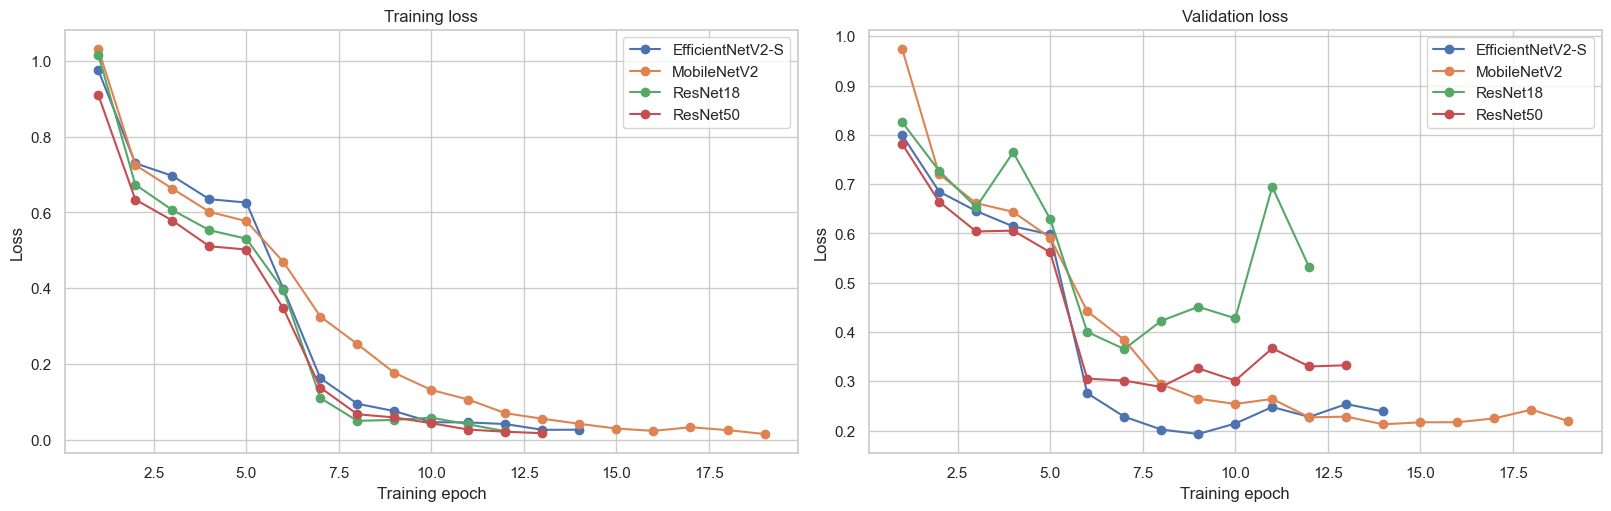

In [21]:
sns.set_theme(style="whitegrid")
fig,axes=plt.subplots(1,2,figsize=(16,5),constrained_layout=True)
for model_name,history in combined.groupby("model",sort=False):
    axes[0].plot(history["global_epoch"],history["train_loss"],marker="o",label=model_name)
    axes[1].plot(history["global_epoch"],history["val_loss"],marker="o",label=model_name)
for ax,title,ylabel in [(axes[0],"Training loss","Loss"),(axes[1],"Validation loss","Loss")]:
    ax.set_title(title); ax.set_xlabel("Training epoch"); ax.set_ylabel(ylabel); ax.legend()
plt.show()

## 4. Training and validation accuracy

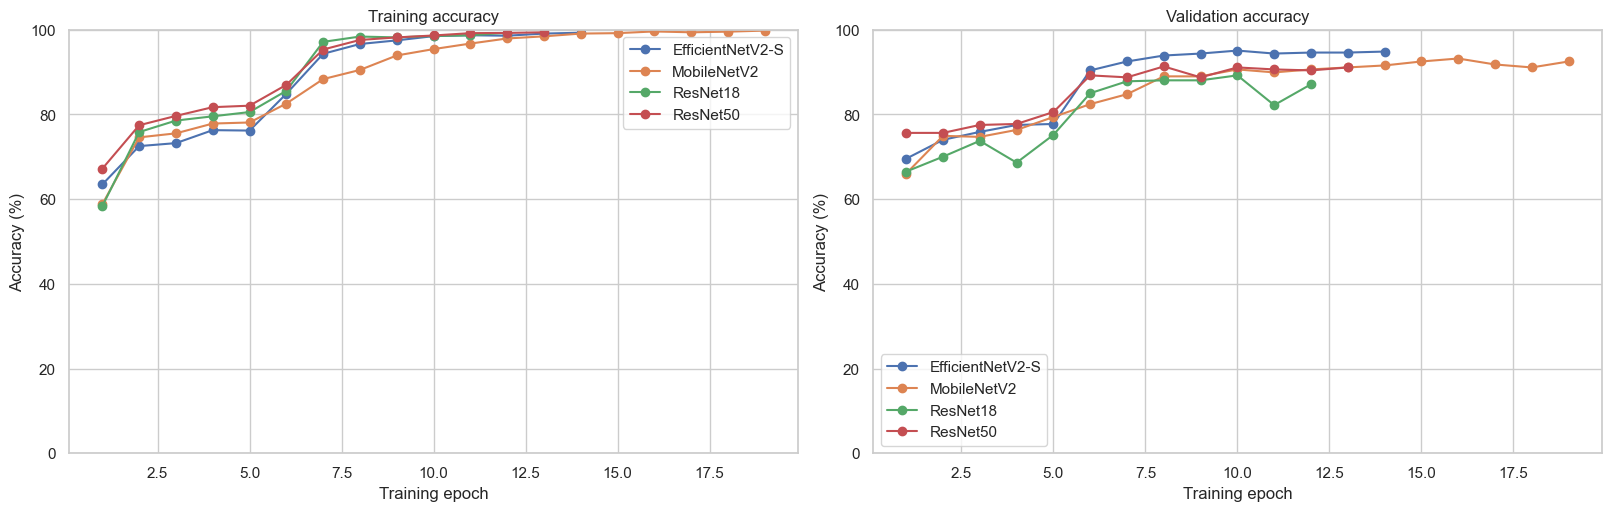

In [22]:
fig,axes=plt.subplots(1,2,figsize=(16,5),constrained_layout=True)
for model_name,history in combined.groupby("model",sort=False):
    axes[0].plot(history["global_epoch"],history["train_accuracy"]*100,marker="o",label=model_name)
    axes[1].plot(history["global_epoch"],history["val_accuracy"]*100,marker="o",label=model_name)
for ax,title in [(axes[0],"Training accuracy"),(axes[1],"Validation accuracy")]:
    ax.set_title(title); ax.set_xlabel("Training epoch"); ax.set_ylabel("Accuracy (%)"); ax.set_ylim(0,100); ax.legend()
plt.show()

## 5. Training speed and GPU memory

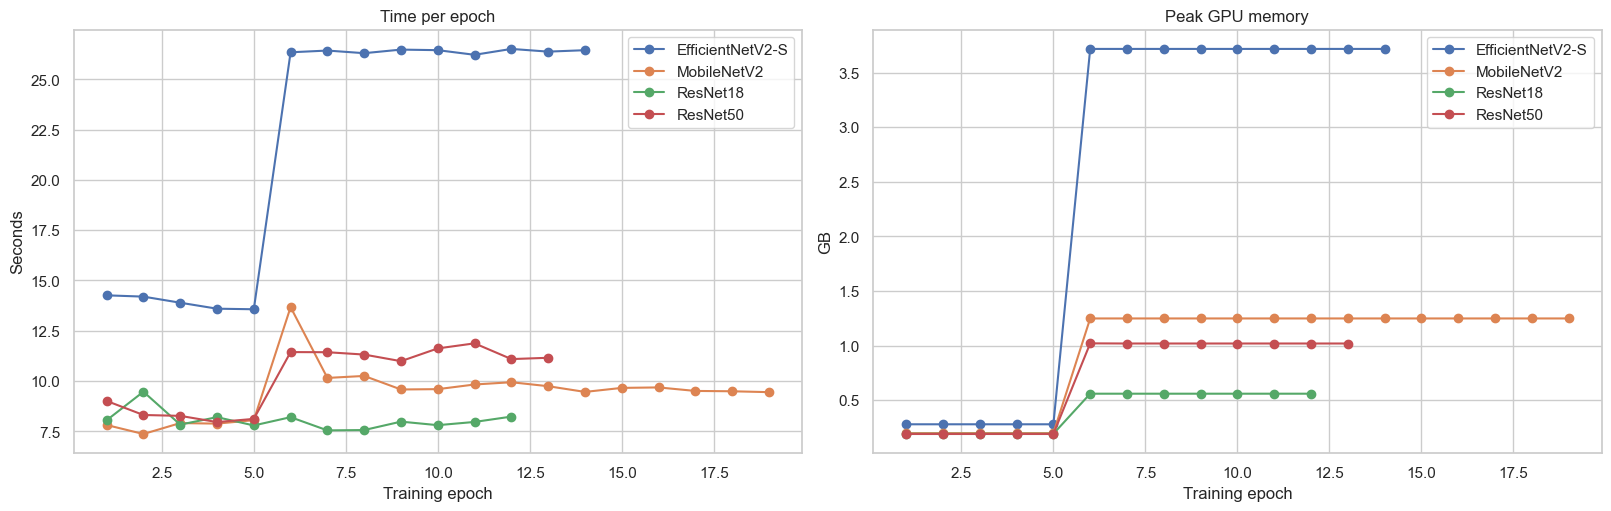

,data_wait_seconds,compute_seconds,validation_seconds,checkpoint_seconds,epoch_seconds
model,,,,,
EfficientNetV2-S,6.542,12.753,2.533,0.043,21.935
MobileNetV2,4.267,3.945,1.182,0.009,9.425
ResNet18,4.447,2.405,1.163,0.016,8.055
ResNet50,4.266,4.477,1.372,0.035,10.200


In [23]:
timing_columns=["data_wait_seconds","compute_seconds","validation_seconds","checkpoint_seconds","epoch_seconds"]
available=[column for column in timing_columns if column in combined.columns]
fig,axes=plt.subplots(1,2,figsize=(16,5),constrained_layout=True)
for model_name,history in combined.groupby("model",sort=False):
    axes[0].plot(history["global_epoch"],history["epoch_seconds"],marker="o",label=model_name)
    if "peak_gpu_memory_gb" in history: axes[1].plot(history["global_epoch"],history["peak_gpu_memory_gb"],marker="o",label=model_name)
axes[0].set_title("Time per epoch"); axes[0].set_xlabel("Training epoch"); axes[0].set_ylabel("Seconds"); axes[0].legend()
axes[1].set_title("Peak GPU memory"); axes[1].set_xlabel("Training epoch"); axes[1].set_ylabel("GB"); axes[1].legend()
plt.show()

display(combined.groupby("model")[available].mean().round(3))

## 6. Best validation checkpoints

In [24]:
best_rows=combined.loc[combined.groupby("model")["val_loss"].idxmin(),["model","phase","global_epoch","val_loss","val_accuracy","best","epoch_seconds"]].sort_values("val_loss")
display(best_rows.reset_index(drop=True))
print("The checkpoint saved by each training notebook is the best validation-loss checkpoint, not necessarily the final epoch.")

,model,phase,global_epoch,val_loss,val_accuracy,best,epoch_seconds
0,EfficientNetV2-S,Fine-tuning,9,0.193119,0.943794,True,26.478720
1,MobileNetV2,Fine-tuning,14,0.212755,0.915691,True,9.460689
2,ResNet50,Fine-tuning,8,0.288531,0.913349,True,11.317652
3,ResNet18,Fine-tuning,7,0.365383,0.878220,True,7.547715


The checkpoint saved by each training notebook is the best validation-loss checkpoint, not necessarily the final epoch.


## 7. Optional comparison of the larger dataset

The larger-dataset histories can be added later by changing `MODEL_DIR` and the four filenames to the `_merged_training_history.csv` files.

,model,epochs,best_val_loss,best_val_accuracy,total_training_seconds,peak_gpu_memory_gb,best_val_loss_epoch
0,EfficientNetV2-S,14,0.037393,0.989705,1102.838256,3.716101,9
1,MobileNetV2,19,0.047456,0.985587,619.276038,1.248781,14
2,ResNet18,18,0.054256,0.984900,632.258207,0.558543,13


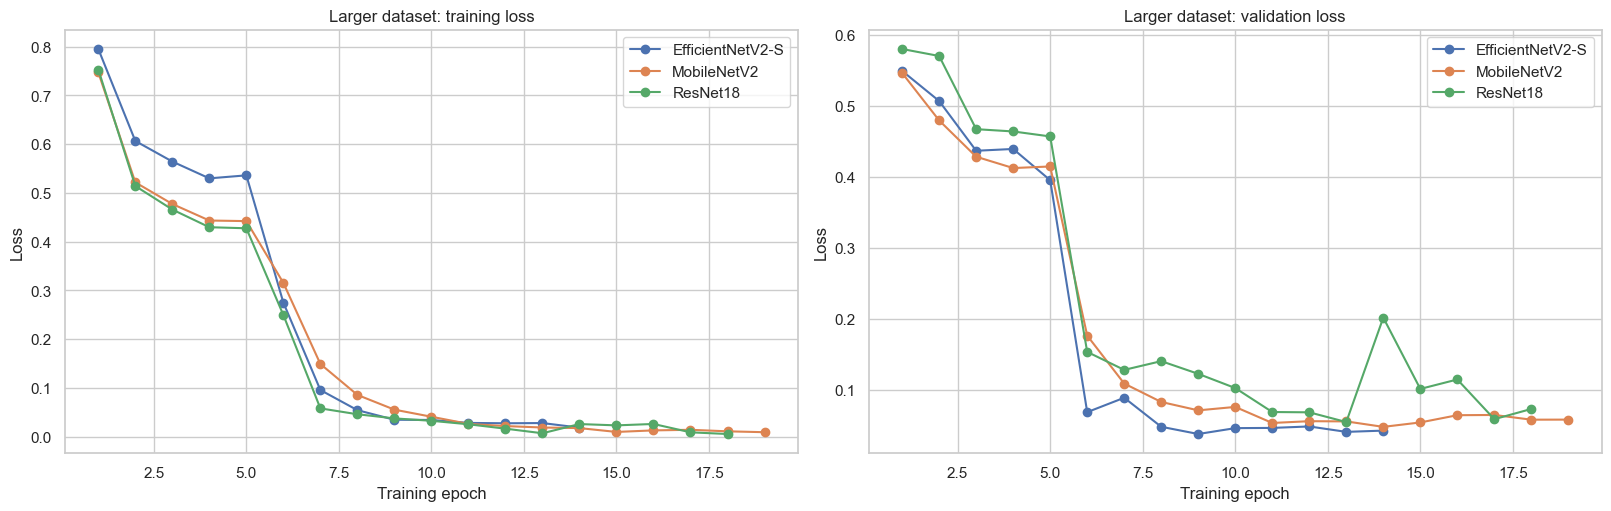

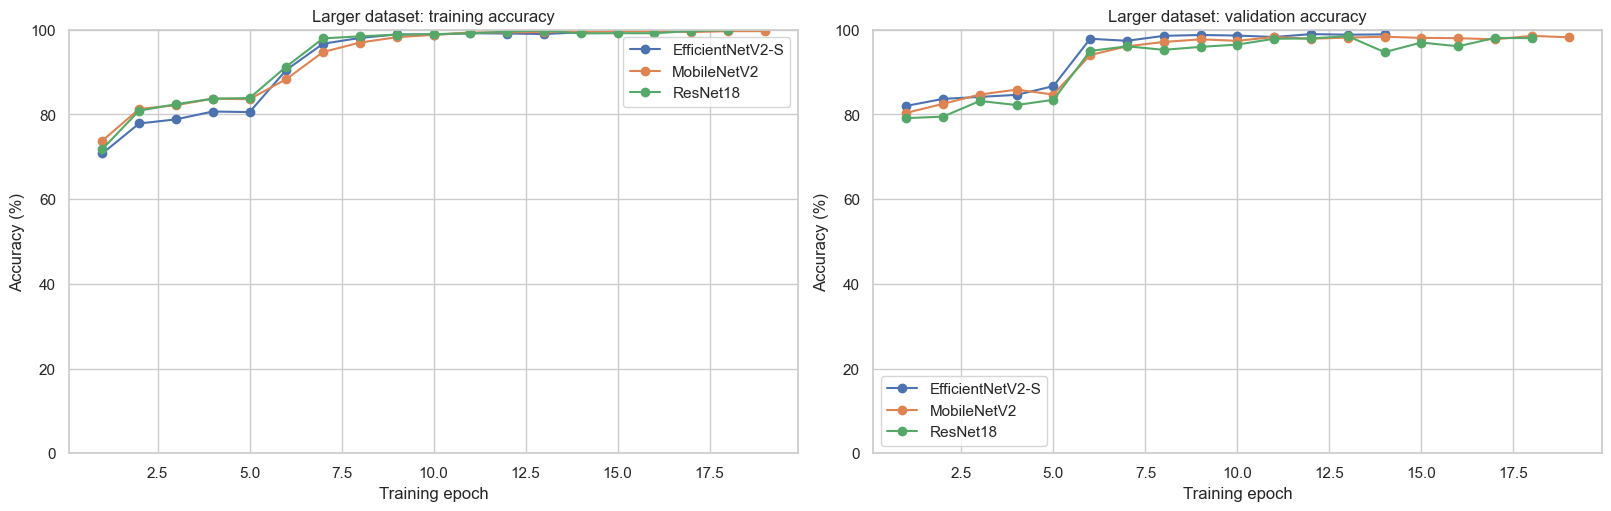

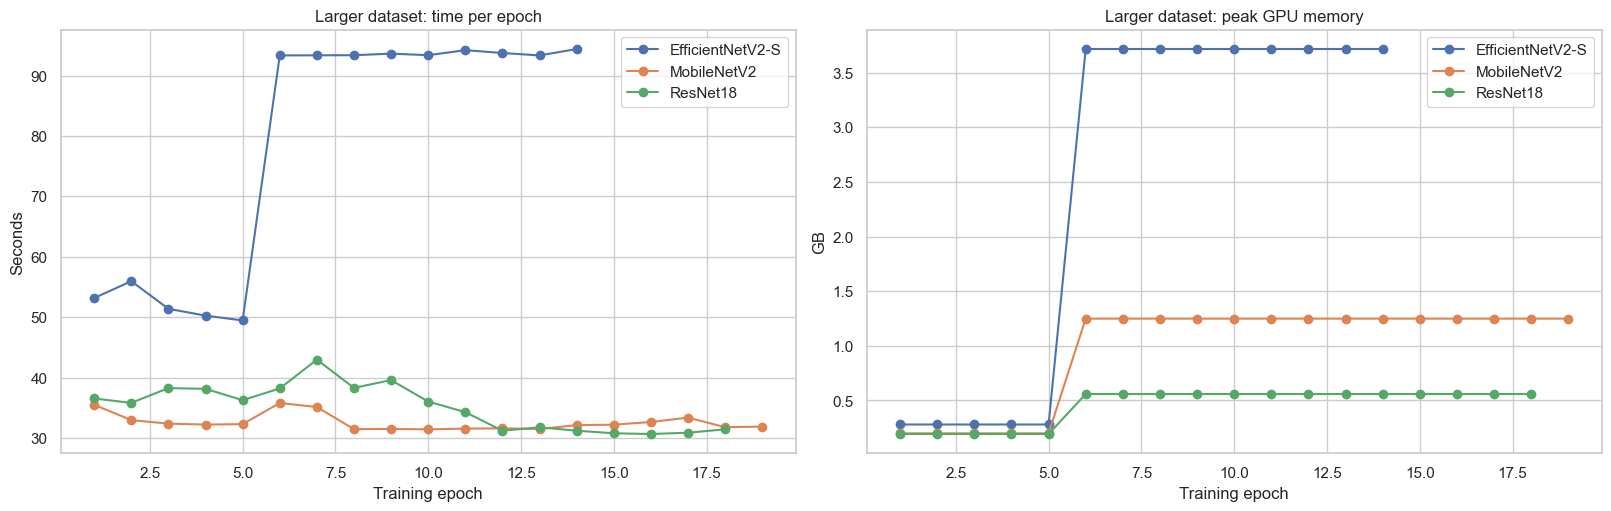

,data_wait_seconds,compute_seconds,validation_seconds,checkpoint_seconds,epoch_seconds
model,,,,,
EfficientNetV2-S,25.457,43.418,9.736,0.033,78.774
MobileNetV2,18.205,9.149,5.183,0.007,32.593
ResNet18,20.461,9.229,5.349,0.022,35.125


,model,phase,global_epoch,val_loss,val_accuracy,best,epoch_seconds
0,EfficientNetV2-S,Fine-tuning,9,0.037393,0.987646,True,93.617114
1,MobileNetV2,Fine-tuning,14,0.047456,0.983528,True,32.127752
2,ResNet18,Fine-tuning,13,0.054256,0.984900,True,31.764877


In [ ]:
# Compare the larger-dataset training histories without modifying the
# smaller-dataset variables.

LARGER_MODEL_DIR=Path("..")/("Larger_Dataset")/"trained_models"
LARGER_HISTORY_FILES = {
    "EfficientNetV2-S": LARGER_MODEL_DIR / "efficientnet_v2_s_merged_training_history.csv",
    "MobileNetV2": LARGER_MODEL_DIR / "mobilenet_v2_merged_training_history.csv",
    "ResNet18": LARGER_MODEL_DIR / "resnet18_merged_training_history.csv",
    "ResNet50": LARGER_MODEL_DIR / "resnet50_merged_training_history.csv",
}

missing_larger = [
    str(path) for path in LARGER_HISTORY_FILES.values() if not path.exists()
]
if missing_larger:
    raise FileNotFoundError(
        "Missing larger-dataset history files:\n" + "\n".join(missing_larger)
    )

larger_histories = []
for model_name, path in LARGER_HISTORY_FILES.items():
    history = pd.read_csv(path)
    required = {
        "phase", "epoch", "train_loss", "train_accuracy",
        "val_loss", "val_accuracy"
    }
    missing_columns = required - set(history.columns)
    if missing_columns:
        raise ValueError(f"{path} is missing columns: {sorted(missing_columns)}")

    history = history.copy()
    history["model"] = model_name
    history["global_epoch"] = range(1, len(history) + 1)
    larger_histories.append(history)

combined_larger = pd.concat(larger_histories, ignore_index=True)

summary_larger = combined_larger.groupby("model", sort=False).agg(
    epochs=("global_epoch", "max"),
    best_val_loss=("val_loss", "min"),
    best_val_accuracy=("val_accuracy", "max"),
    total_training_seconds=("epoch_seconds", "sum"),
    peak_gpu_memory_gb=("peak_gpu_memory_gb", "max"),
).reset_index()

best_larger = combined_larger.loc[
    combined_larger.groupby("model")["val_loss"].idxmin()
].copy()

summary_larger["best_val_loss_epoch"] = (
    best_larger.set_index("model")
    .loc[summary_larger["model"], "global_epoch"]
    .to_numpy()
)

display(summary_larger.sort_values("best_val_loss"))

# Loss comparison
fig, axes = plt.subplots(1, 2, figsize=(16, 5), constrained_layout=True)

for model_name, history in combined_larger.groupby("model", sort=False):
    axes[0].plot(
        history["global_epoch"], history["train_loss"],
        marker="o", label=model_name
    )
    axes[1].plot(
        history["global_epoch"], history["val_loss"],
        marker="o", label=model_name
    )

axes[0].set_title("Larger dataset: training loss")
axes[1].set_title("Larger dataset: validation loss")

for axis in axes:
    axis.set_xlabel("Training epoch")
    axis.set_ylabel("Loss")
    axis.legend()

plt.show()

# Accuracy comparison
fig, axes = plt.subplots(1, 2, figsize=(16, 5), constrained_layout=True)

for model_name, history in combined_larger.groupby("model", sort=False):
    axes[0].plot(
        history["global_epoch"], history["train_accuracy"] * 100,
        marker="o", label=model_name
    )
    axes[1].plot(
        history["global_epoch"], history["val_accuracy"] * 100,
        marker="o", label=model_name
    )

axes[0].set_title("Larger dataset: training accuracy")
axes[1].set_title("Larger dataset: validation accuracy")

for axis in axes:
    axis.set_xlabel("Training epoch")
    axis.set_ylabel("Accuracy (%)")
    axis.set_ylim(0, 100)
    axis.legend()

plt.show()

# Training speed and GPU memory
fig, axes = plt.subplots(1, 2, figsize=(16, 5), constrained_layout=True)

for model_name, history in combined_larger.groupby("model", sort=False):
    axes[0].plot(
        history["global_epoch"], history["epoch_seconds"],
        marker="o", label=model_name
    )
    axes[1].plot(
        history["global_epoch"], history["peak_gpu_memory_gb"],
        marker="o", label=model_name
    )

axes[0].set_title("Larger dataset: time per epoch")
axes[0].set_ylabel("Seconds")
axes[1].set_title("Larger dataset: peak GPU memory")
axes[1].set_ylabel("GB")

for axis in axes:
    axis.set_xlabel("Training epoch")
    axis.legend()

plt.show()

available_larger = [
    column for column in timing_columns
    if column in combined_larger.columns
]

display(
    combined_larger.groupby("model")[available_larger]
    .mean()
    .round(3)
)

# Best validation-loss checkpoints
best_larger_rows = best_larger[
    [
        "model", "phase", "global_epoch", "val_loss",
        "val_accuracy", "best", "epoch_seconds"
    ]
].sort_values("val_loss")

display(best_larger_rows.reset_index(drop=True))